## 분석 설계

In [ ]:
# 항목	설정
# 분석기간	2021-01-01 ~ 2026-10-23
# 삼성전자	005930, 일별 주가수익률
# 환율	USD/KRW, 일별 환율 변화율
# VAR	OLS 추정
# BVAR	정규 사전분포를 이용한 베이지안 추정
# LBVAR	Minnesota/Litterman 방식의 사전분포 적용
# 비교	회귀계수, RMSE, MAE
# 데이터는 다음 출처를 사용합니다.
# - 삼성전자 및 환율: FinanceDataReader
# - 국고채 3년 수익률: pykrx의 장외 채권수익률 API
# 두 라이브러리 모두 해당 데이터 조회 기능을 문서화하고 있습니다. 

## 라이브러리

In [2]:
%pip install -U pandas numpy matplotlib scipy statsmodels
%pip install -U finance-datareader pykrx

   ---------------------------------------- 0.0/11.0 MB ? eta -:--:--
   ---- ----------------------------------- 1.3/11.0 MB 7.4 MB/s eta 0:00:02
   ------------ --------------------------- 3.4/11.0 MB 8.4 MB/s eta 0:00:01
   ------------------- -------------------- 5.2/11.0 MB 8.4 MB/s eta 0:00:01
   --------------------------- ------------ 7.6/11.0 MB 9.0 MB/s eta 0:00:01
   ------------------------------------ --- 10.0/11.0 MB 9.5 MB/s eta 0:00:01
   ---------------------------------------- 11.0/11.0 MB 9.4 MB/s  0:00:01
   ---------------------------------------- 0.0/9.3 MB ? eta -:--:--
   ---------- ----------------------------- 2.4/9.3 MB 11.2 MB/s eta 0:00:01
   -------------------- ------------------- 4.7/9.3 MB 11.4 MB/s eta 0:00:01
   ------------------------------ --------- 7.1/9.3 MB 11.5 MB/s eta 0:00:01
   ------------------------------------- -- 8.7/9.3 MB 11.0 MB/s eta 0:00:01
   ---------------------------------------- 9.3/9.3 MB 9.2 MB/s  0:00:01
   ----------------

  You can safely remove it manually.
  You can safely remove it manually.
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
pykrx 1.2.8 requires pandas<3.0,>=2.2.0, but you have pandas 3.1.0 which is incompatible.

[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: C:\Users\JYB\AppData\Local\Programs\Python\Python311\python.exe -m pip install --upgrade pip


  Using cached pandas-2.3.3-cp311-cp311-win_amd64.whl.metadata (19 kB)
   ---------------------------------------- 0.0/2.2 MB ? eta -:--:--
   ---------------------------- ----------- 1.6/2.2 MB 7.6 MB/s eta 0:00:01
   ---------------------------------------- 2.2/2.2 MB 7.7 MB/s  0:00:00
Using cached pandas-2.3.3-cp311-cp311-win_amd64.whl (11.3 MB)
   ---------------------------------------- 0.0/4.0 MB ? eta -:--:--
   ------------------ --------------------- 1.8/4.0 MB 9.1 MB/s eta 0:00:01
   ------------------------------- -------- 3.1/4.0 MB 8.8 MB/s eta 0:00:01
   --------------------------------- ------ 3.4/4.0 MB 5.0 MB/s eta 0:00:01
   ---------------------------------------- 4.0/4.0 MB 5.5 MB/s  0:00:00
   ---------------------------------------- 0.0/9.7 MB ? eta -:--:--
   --------- ------------------------------ 2.4/9.7 MB 11.2 MB/s eta 0:00:01
   ------------------- -------------------- 4.7/9.7 MB 11.4 MB/s eta 0:00:01
   ----------------------------- ---------- 7.1/9.7 MB 1


[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: C:\Users\JYB\AppData\Local\Programs\Python\Python311\python.exe -m pip install --upgrade pip


In [4]:
%pip install -U scikit-learn

   ---------------------------------------- 0.0/8.3 MB ? eta -:--:--
   -------- ------------------------------- 1.8/8.3 MB 12.6 MB/s eta 0:00:01
   -------------------- ------------------- 4.2/8.3 MB 10.5 MB/s eta 0:00:01
   ---------------------------- ----------- 6.0/8.3 MB 10.5 MB/s eta 0:00:01
   ---------------------------------------  8.1/8.3 MB 10.3 MB/s eta 0:00:01
   ---------------------------------------- 8.3/8.3 MB 9.7 MB/s  0:00:00

   ------------- -------------------------- 1/3 [joblib]
   ------------- -------------------------- 1/3 [joblib]
   ------------- -------------------------- 1/3 [joblib]
   ------------- -------------------------- 1/3 [joblib]
   ------------- -------------------------- 1/3 [joblib]
   ------------- -------------------------- 1/3 [joblib]
   ------------- -------------------------- 1/3 [joblib]
   ------------- -------------------------- 1/3 [joblib]
   ------------- -------------------------- 1/3 [joblib]
   ------------- -------------------


[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: C:\Users\JYB\AppData\Local\Programs\Python\Python311\python.exe -m pip install --upgrade pip


In [5]:
from sklearn.metrics import mean_squared_error, mean_absolute_error

print("scikit-learn 불러오기 성공")

scikit-learn 불러오기 성공


In [6]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import FinanceDataReader as fdr
from pykrx import bond

# statsmodels: 통계분석을 위한 파이썬 라이브러리
# tsa: Time Series Analysis(시계열 분석)
# api: 시계열 분석 기능을 제공하는 인터페이스
# VAR: 벡터자기회귀(Vector Autoregression) 모형 클래스
from statsmodels.tsa.api import VAR
from statsmodels.tsa.stattools import adfuller  # adfuller는 ADF(Augmented Dickey-Fuller) 단위근 검정을 수행하는 함수

# cho_factor: 촐레스키 분해: 촐레스키 분해(Cholesky Decomposition)는 대칭 양의 정부호 행렬을 삼각행렬의 곱으로 분해하는 방법
from scipy.linalg import cho_factor, cho_solve
from sklearn.metrics import mean_squared_error, mean_absolute_error

plt.rcParams["axes.unicode_minus"] = False

## 실제 금융데이터 다운로드

In [8]:
#삼성전자 주가와 원/달러 환율을 다운로드
start = "2021-01-01"
end = "2026-10-24"  # 종료일은 미포함

# 1. 삼성전자 주가
samsung = fdr.DataReader("005930", start, end)

# 2. 원/달러 환율
fx = fdr.DataReader("USD/KRW", start, end)

print("삼성전자 데이터")
print(samsung.head())

print("\n원/달러 환율 데이터")
print(fx.head())

삼성전자 데이터
             Open   High    Low  Close    Volume    Change
Date                                                      
2021-01-04  81000  84400  80200  83000  38655276  0.024691
2021-01-05  81600  83900  81600  83900  35335669  0.010843
2021-01-06  83300  84500  82100  82200  42089013 -0.020262
2021-01-07  82800  84200  82700  82900  32644642  0.008516
2021-01-08  83300  90000  83000  88800  59013307  0.071170

원/달러 환율 데이터
                   Open         High          Low        Close  Volume  \
2020-12-31  1086.420044  1088.800049  1082.089966  1086.420044     0.0   
2021-01-01  1083.500000  1088.500000  1083.500000  1084.650024     0.0   
2021-01-04  1084.729980  1086.469971  1079.219971  1084.729980     0.0   
2021-01-05  1085.609985  1089.729980  1081.670044  1086.619995     0.0   
2021-01-06  1085.650024  1088.589966  1083.250000  1086.449951     0.0   

              Adj Close  
2020-12-31  1086.420044  
2021-01-01  1084.650024  
2021-01-04  1084.729980  
2021-01-05  1086

### 주가수익률과 환율 변화율 계산

In [11]:
# 날짜 인덱스 통일
samsung.index = pd.to_datetime(samsung.index)
fx.index = pd.to_datetime(fx.index)

# 두 데이터 결합
raw = pd.concat(
    [
        samsung["Close"].rename("Samsung_Close"),
        fx["Close"].rename("USD_KRW")
    ],
    axis=1,
    join="inner"
).sort_index().dropna()

# 로그수익률 계산
df = pd.DataFrame(index=raw.index)

df["Samsung_Return"] = (
    100 * np.log(raw["Samsung_Close"]).diff()
)

df["FX_Return"] = (
    100 * np.log(raw["USD_KRW"]).diff()
)

df = df.replace([np.inf, -np.inf], np.nan).dropna()

print(df.head())
print("\n관측치:", len(df))
print("\n기초통계량")
print(df.describe())

            Samsung_Return  FX_Return
2021-01-05        1.078501   0.174087
2021-01-06       -2.047031  -0.015650
2021-01-07        0.847976   0.046011
2021-01-08        6.875159   0.561464
2021-01-11        2.447286  -0.022874

관측치: 1247

기초통계량
       Samsung_Return    FX_Return
count     1247.000000  1247.000000
mean         0.076140     0.016105
std          2.680427     0.648805
min        -17.354087    -3.498781
25%         -1.111270    -0.351593
50%          0.000000     0.038946
75%          1.123958     0.413852
max         15.295750     2.173950


### 데이터 그래프

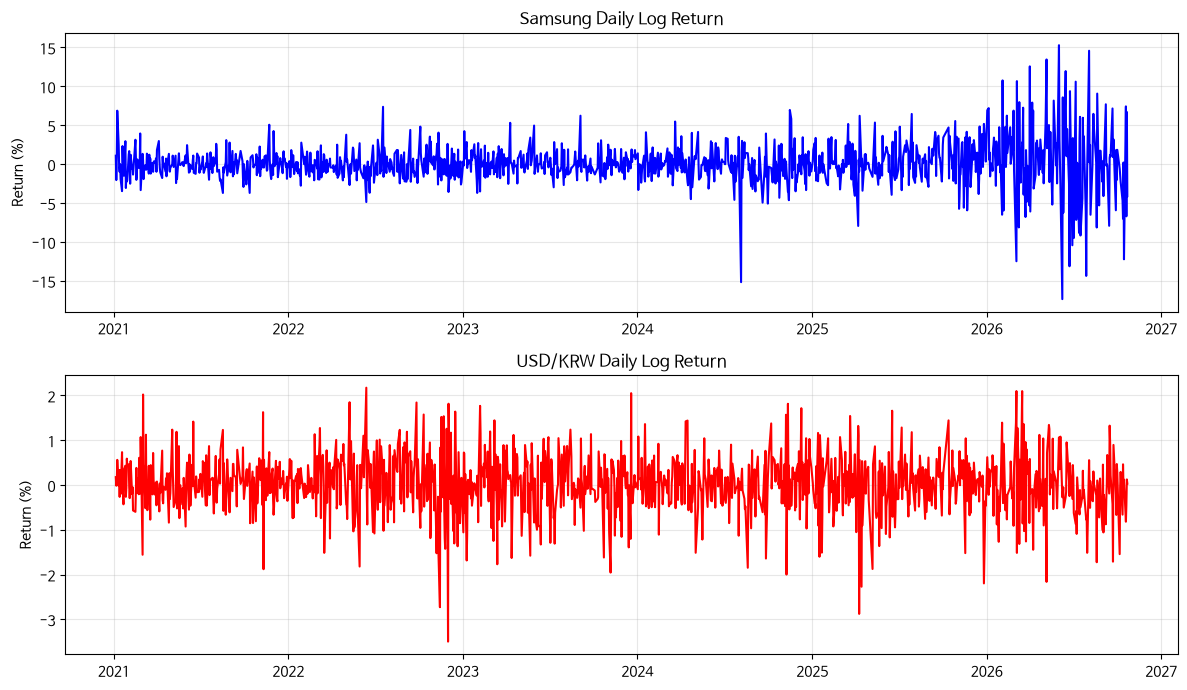

In [12]:
fig, axes = plt.subplots(2, 1, figsize=(12, 7))

axes[0].plot(
    df.index,
    df["Samsung_Return"],
    color="blue"
)
axes[0].set_title("Samsung Daily Log Return")
axes[0].set_ylabel("Return (%)")
axes[0].grid(alpha=0.3)

axes[1].plot(
    df.index,
    df["FX_Return"],
    color="red"
)
axes[1].set_title("USD/KRW Daily Log Return")
axes[1].set_ylabel("Return (%)")
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

### 정상성 검정(ADF)

In [ ]:
# ADF 검정의 귀무가설은 단위근이 존재한다는 것입니다.
# 일반적으로 p-value가 0.05보다 작으면 단위근 귀무가설을 기각합니다.

In [14]:
for col in df.columns:

    result = adfuller(
        df[col],
        autolag="AIC"
    )

    print(f"\n변수: {col}")
    print(f"ADF 통계량: {result[0]:.4f}")
    print(f"p-value: {result[1]:.4f}")

    if result[1] < 0.05:
        print("단위근 귀무가설 기각")
    else:
        print("단위근 귀무가설 기각 불가")


변수: Samsung_Return
ADF 통계량: -7.5832
p-value: 0.0000
단위근 귀무가설 기각

변수: FX_Return
ADF 통계량: -39.6887
p-value: 0.0000
단위근 귀무가설 기각


C:\Users\JYB\AppData\Local\Temp\ipykernel_27528\1896187990.py:3: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  result = adfuller(
C:\Users\JYB\AppData\Local\Temp\ipykernel_27528\1896187990.py:3: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  result = adfuller(


### 학습 데이터와 테스트 데이터 분리

In [16]:
# 전체 데이터의 80%는 모형 추정, 20%는 예측 성능 평가에 사용
p = 2

split = int(len(df) * 0.8)

train = df.iloc[:split].copy()
test = df.iloc[split:].copy()

print("학습 데이터:", train.shape)
print("테스트 데이터:", test.shape)

학습 데이터: (997, 2)
테스트 데이터: (250, 2)


In [17]:
# 세 모형에 동일한 설명변수를 제공하기 위해 회귀행렬을 생성
# 설명변수는 const, Samsung_Return_L1, FX_Return_L1, Samsung_Return_L2, FX_Return_L2의 5개

def make_var_matrix(data, p=2):

    X = pd.DataFrame(index=data.index)
    X["const"] = 1.0

    for lag in range(1, p + 1):
        for col in data.columns:
            X[f"{col}_L{lag}"] = data[col].shift(lag)

    combined = pd.concat(
        [X, data.add_prefix("Y_")],
        axis=1
    ).dropna()

    X = combined[X.columns]

    Y = combined[
        [f"Y_{col}" for col in data.columns]
    ]

    return X, Y


X_all, Y_all = make_var_matrix(df, p)

X_train = X_all.loc[train.index.intersection(X_all.index)]
Y_train = Y_all.loc[X_train.index]

X_test = X_all.loc[test.index.intersection(X_all.index)]
Y_test = Y_all.loc[X_test.index]

X = X_train.to_numpy(dtype=float)
Y = Y_train.to_numpy(dtype=float)

print("설명변수")
print(X_train.head())

설명변수
            const  Samsung_Return_L1  FX_Return_L1  Samsung_Return_L2  \
2021-01-07    1.0          -2.047031     -0.015650           1.078501   
2021-01-08    1.0           0.847976      0.046011          -2.047031   
2021-01-11    1.0           6.875159      0.561464           0.847976   
2021-01-12    1.0           2.447286     -0.022874           6.875159   
2021-01-13    1.0          -0.440529      0.331618           2.447286   

            FX_Return_L2  
2021-01-07      0.174087  
2021-01-08     -0.015650  
2021-01-11      0.046011  
2021-01-12      0.561464  
2021-01-13     -0.022874  


## VAR 모형: OLS 계수 추정

var_model = VAR(train)

var_result = var_model.fit(p, trend="c")

print(var_result.summary())

In [19]:
# 회귀계수를 확인
# 이 코드에서는 삼성전자 방정식과 환율 방정식의 회귀계수를 동시에 계산합니다.
beta_ols = np.linalg.lstsq(
    X, Y, rcond=None
)[0]

coef_var = pd.DataFrame(
    beta_ols,
    index=X_train.columns,
    columns=df.columns
)

print("VAR 계수")
print(coef_var.round(5))

VAR 계수
                   Samsung_Return  FX_Return
const                    -0.01673    0.02859
Samsung_Return_L1        -0.03197   -0.05240
FX_Return_L1             -0.01348   -0.15455
Samsung_Return_L2        -0.05132   -0.00497
FX_Return_L2              0.00703   -0.02143


In [20]:
# 통계적으로 유의한 계수인지 확인
print(var_result.summary())

  Summary of Regression Results   
Model:                         VAR
Method:                        OLS
Date:           Mon, 26, Oct, 2026
Time:                     11:12:50
--------------------------------------------------------------------
No. of Equations:         2.00000    BIC:                   0.267090
Nobs:                     995.000    HQIC:                  0.236548
Log likelihood:          -2922.05    FPE:                    1.24336
AIC:                     0.217816    Det(Omega_mle):         1.23096
--------------------------------------------------------------------
Results for equation Samsung_Return
                       coefficient       std. error           t-stat            prob
------------------------------------------------------------------------------------
const                    -0.016731         0.056297           -0.297           0.766
L1.Samsung_Return        -0.031971         0.032266           -0.991           0.322
L1.FX_Return             -0.013481 

In [21]:
# 삼성전자 방정식에서 환율 변수의 p-value를 확인
print("VAR 계수별 p-value")
print(var_result.pvalues)

VAR 계수별 p-value
                   Samsung_Return  FX_Return
const                    0.766325   0.157279
L1.Samsung_Return        0.321764   0.000006
L1.FX_Return             0.880955   0.000002
L2.Samsung_Return        0.115212   0.671021
L2.FX_Return             0.937305   0.504020


In [ ]:
# 환율의 두 시차가 삼성전자 수익률 예측에 공동으로 기여하는지 확인하려면 그랜저 인과성 검정을 사용

In [22]:
# 환율 -> 삼성전자
test_fx_to_samsung = var_result.test_causality(
    caused="Samsung_Return",
    causing=["FX_Return"],
    kind="f"
)

print(test_fx_to_samsung.summary())

# 삼성전자 -> 환율
test_samsung_to_fx = var_result.test_causality(
    caused="FX_Return",
    causing=["Samsung_Return"],
    kind="f"
)

print(test_samsung_to_fx.summary())

Granger causality F-test. H_0: FX_Return does not Granger-cause Samsung_Return. Conclusion: fail to reject H_0 at 5% significance level.
Test statistic Critical value p-value     df   
-----------------------------------------------
       0.01647          3.000   0.984 (2, 1980)
-----------------------------------------------
Granger causality F-test. H_0: Samsung_Return does not Granger-cause FX_Return. Conclusion: reject H_0 at 5% significance level.
Test statistic Critical value p-value     df   
-----------------------------------------------
         10.24          3.000   0.000 (2, 1980)
-----------------------------------------------


## BVAR 모형: 베이지안 추정

In [ ]:
# BVAR에서는 정규 사전분포를 적용하겠습니다.
# 다음 코드는 오차분산을 OLS 추정값으로 고정하고, 그 조건 아래 회귀계수의 사후평균을 계산하는 단순화된 BVAR입니다.
# 사전분산 100은 예시 설정입니다. 사전분산이 클수록 계수에 대한 사전 제약이 약해집니다.

In [23]:
# OLS 잔차
residuals = Y - X @ beta_ols

# 방정식별 잔차분산
sigma2 = np.var(
    residuals,
    axis=0,
    ddof=X.shape[1]
)

def bayesian_var(
    X, Y,
    prior_mean,
    prior_var,
    sigma2
):

    n_coef = X.shape[1]
    n_eq = Y.shape[1]

    beta_post = np.zeros((n_coef, n_eq))

    for j in range(n_eq):

        prior_precision = np.diag(
            1.0 / prior_var[:, j]
        )

        posterior_precision = (
            X.T @ X / sigma2[j]
            + prior_precision
        )

        posterior_rhs = (
            X.T @ Y[:, j] / sigma2[j]
            + prior_precision @ prior_mean[:, j]
        )

        factor = cho_factor(
            posterior_precision,
            lower=True
        )

        beta_post[:, j] = cho_solve(
            factor,
            posterior_rhs
        )

    return beta_post


n_coef = X.shape[1]
n_eq = Y.shape[1]

# BVAR 사전분포
bvar_prior_mean = np.zeros((n_coef, n_eq))

bvar_prior_var = np.full(
    (n_coef, n_eq),
    100.0
)

# 상수항은 약하게 축소
bvar_prior_var[0, :] = 1e6

beta_bvar = bayesian_var(
    X, Y,
    bvar_prior_mean,
    bvar_prior_var,
    sigma2
)

coef_bvar = pd.DataFrame(
    beta_bvar,
    index=X_train.columns,
    columns=df.columns
)

print("BVAR 계수")
print(coef_bvar.round(5))

BVAR 계수
                   Samsung_Return  FX_Return
const                    -0.01673    0.02859
Samsung_Return_L1        -0.03197   -0.05240
FX_Return_L1             -0.01348   -0.15455
Samsung_Return_L2        -0.05132   -0.00497
FX_Return_L2              0.00703   -0.02143


### BVAR의 계수 축소 효과를 직접 확인해 보기

In [24]:
# 사전분산을 100에서 0.01로 변경
# 사전분산을 작게 설정
bvar_prior_var = np.full(
    (n_coef, n_eq),
    0.01
)

# 상수항은 약하게 축소
bvar_prior_var[0, :] = 1e6

# BVAR 다시 추정
beta_bvar_strong = bayesian_var(
    X, Y,
    bvar_prior_mean,
    bvar_prior_var,
    sigma2
)

coef_bvar_strong = pd.DataFrame(
    beta_bvar_strong,
    index=X_train.columns,
    columns=df.columns
)

print("강한 사전분포를 적용한 BVAR 계수")
print(coef_bvar_strong.round(5))

강한 사전분포를 적용한 BVAR 계수
                   Samsung_Return  FX_Return
const                    -0.01674    0.02816
Samsung_Return_L1        -0.02847   -0.05074
FX_Return_L1             -0.00589   -0.13935
Samsung_Return_L2        -0.04631   -0.00396
FX_Return_L2              0.00589   -0.01738


### VAR과 BVAR의 차이를 수치로 비교

In [25]:
comparison = pd.DataFrame({
    "VAR": coef_var["Samsung_Return"],
    "BVAR_Weak": coef_bvar["Samsung_Return"],
    "BVAR_Strong": coef_bvar_strong["Samsung_Return"]
})

print(comparison.round(8))

                        VAR  BVAR_Weak  BVAR_Strong
const             -0.016731  -0.016731    -0.016742
Samsung_Return_L1 -0.031971  -0.031970    -0.028467
FX_Return_L1      -0.013481  -0.013480    -0.005888
Samsung_Return_L2 -0.051324  -0.051323    -0.046315
FX_Return_L2       0.007027   0.007027     0.005888


In [26]:
# 계수 차이를 직접 확인
difference = coef_bvar - coef_var

print("BVAR - VAR 계수 차이")
print(difference.round(10))

print(
    "최대 절대 차이:",
    difference.abs().to_numpy().max()
)

BVAR - VAR 계수 차이
                   Samsung_Return     FX_Return
const               -1.500000e-08 -4.840000e-08
Samsung_Return_L1    4.292000e-07  1.787000e-07
FX_Return_L1         1.401100e-06  1.687300e-06
Samsung_Return_L2    5.829000e-07  1.136000e-07
FX_Return_L2        -8.120000e-08  4.722000e-07
최대 절대 차이: 1.6872636647846662e-06


## LBVAR 모형: Minnesota Prior

In [ ]:
#LBVAR에서는 자기 자신의 시차 계수와 다른 변수의 시차 계수에 서로 다른 사전분산을 적용합니다.
# 수익률 변수에 맞춰 모든 시차 계수의 사전평균을 0으로 설정합니다. 전통적인 수준변수 기반 Litterman 사전분포에서 자기 1차 시차의 사전평균을 1로 두는 설정과는 다릅니다.

In [28]:
def minnesota_prior(
    data,
    p=2,
    lam=0.2,
    cross=0.5,
    decay=1.0
):

    variables = list(data.columns)

    n_eq = len(variables)
    n_coef = 1 + n_eq * p

    prior_mean = np.zeros((n_coef, n_eq))
    prior_var = np.zeros((n_coef, n_eq))

    # 상수항
    prior_var[0, :] = 1e6

    scale = data.std(ddof=1).to_numpy()

    for eq_idx in range(n_eq):

        row = 1

        for lag in range(1, p + 1):

            for var_idx in range(n_eq):

                if eq_idx == var_idx:
                    shrink = 1.0
                else:
                    shrink = cross

                prior_std = (
                    lam
                    * shrink
                    / (lag ** decay)
                    * scale[eq_idx]
                    / scale[var_idx]
                )

                prior_var[row, eq_idx] = prior_std ** 2

                row += 1

    return prior_mean, prior_var


lbvar_mean, lbvar_var = minnesota_prior(
    train,
    p=p,
    lam=0.2,
    cross=0.5
)

beta_lbvar = bayesian_var(
    X, Y,
    lbvar_mean,
    lbvar_var,
    sigma2
)

coef_lbvar = pd.DataFrame(
    beta_lbvar,
    index=X_train.columns,
    columns=df.columns
)

print("LBVAR 계수")
print(coef_lbvar.round(5))

LBVAR 계수
                   Samsung_Return  FX_Return
const                    -0.01670    0.02845
Samsung_Return_L1        -0.03085   -0.04728
FX_Return_L1             -0.01037   -0.14746
Samsung_Return_L2        -0.04649   -0.00309
FX_Return_L2              0.00694   -0.01797


## VAR·BVAR·LBVAR 회귀계수 비교

In [29]:
comparison = pd.DataFrame({

    "VAR": coef_var["Samsung_Return"],

    "BVAR": coef_bvar["Samsung_Return"],

    "LBVAR": coef_lbvar["Samsung_Return"]

})

print(comparison.round(5))

                       VAR     BVAR    LBVAR
const             -0.01673 -0.01673 -0.01670
Samsung_Return_L1 -0.03197 -0.03197 -0.03085
FX_Return_L1      -0.01348 -0.01348 -0.01037
Samsung_Return_L2 -0.05132 -0.05132 -0.04649
FX_Return_L2       0.00703  0.00703  0.00694


## 예측 성능 비교: RMSE와 MAE

In [32]:
# RMSE와 MAE는 작을수록 예측오차가 작습니다.
X_te = X_test.to_numpy(dtype=float)
Y_te = Y_test.to_numpy(dtype=float)

# 각 모형의 하루 앞 예측
pred_var = X_te @ beta_ols
pred_bvar = X_te @ beta_bvar
pred_lbvar = X_te @ beta_lbvar

# 삼성전자 수익률 실제값
actual = Y_te[:, 0]

predictions = {
    "VAR": pred_var[:, 0],
    "BVAR": pred_bvar[:, 0],
    "LBVAR": pred_lbvar[:, 0]
}

results = []

for name, pred in predictions.items():

    rmse = np.sqrt(
        mean_squared_error(actual, pred)
    )

    mae = mean_absolute_error(
        actual, pred
    )

    results.append({
        "Model": name,
        "RMSE": rmse,
        "MAE": mae
    })

performance = pd.DataFrame(results)

print(performance.round(5))

   Model     RMSE      MAE
0    VAR  4.80840  3.51302
1   BVAR  4.80841  3.51302
2  LBVAR  4.80915  3.51149


###  실제값과 예측값 그래프

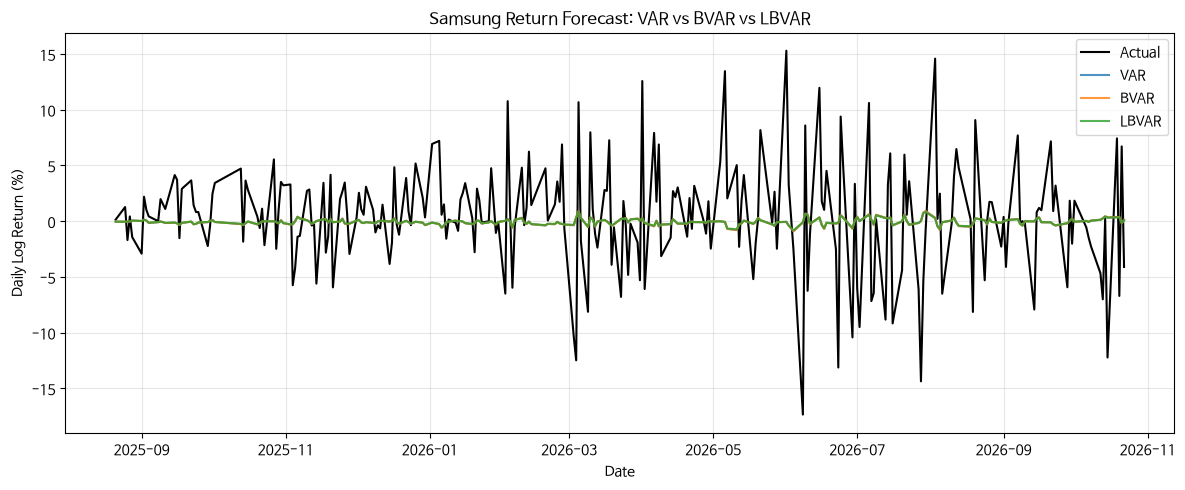

In [33]:
plt.figure(figsize=(12, 5))

plt.plot(
    Y_test.index,
    actual,
    label="Actual",
    color="black",
    linewidth=1.5
)

plt.plot(
    Y_test.index,
    predictions["VAR"],
    label="VAR",
    alpha=0.8
)

plt.plot(
    Y_test.index,
    predictions["BVAR"],
    label="BVAR",
    alpha=0.8
)

plt.plot(
    Y_test.index,
    predictions["LBVAR"],
    label="LBVAR",
    alpha=0.8
)

plt.title(
    "Samsung Return Forecast: VAR vs BVAR vs LBVAR"
)

plt.xlabel("Date")
plt.ylabel("Daily Log Return (%)")

plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

### 단순 기준모형(Benchmark) 과 비교

In [ ]:
# 삼성전자 수익률의 RMSE가 약 4.81%p라는 것은 하루 앞 로그수익률 예측에서 제곱평균제곱근 오차가 약 4.81%p라는 의미입니다.
# 이 수치가 좋은지 나쁜지 판단하려면 단순 기준모형(Benchmark) 과 비교해야 합니다.

In [34]:
# 기준모형: 다음 날 삼성전자 수익률은 0%라고 예측
benchmark_pred = np.zeros_like(actual)

benchmark_rmse = np.sqrt(
    mean_squared_error(actual, benchmark_pred)
)

benchmark_mae = mean_absolute_error(
    actual, benchmark_pred
)

print("Benchmark RMSE:", round(benchmark_rmse, 5))
print("Benchmark MAE:", round(benchmark_mae, 5))

Benchmark RMSE: 4.8296
Benchmark MAE: 3.49844
